# Метод гистограмм ориентированных градиентов (HOG)

Семинарист: [Федорова Валерия Сергеевна](https://www.hse.ru/org/persons/510438167)

Скрипт подготовлен по материалам: [Проворовой (Радыгиной) Анны Александровны](https://www.hse.ru/staff/provorovaaa/)

## Задание: https://disk.360.yandex.ru/i/n-B6_ygMNV8pAQ

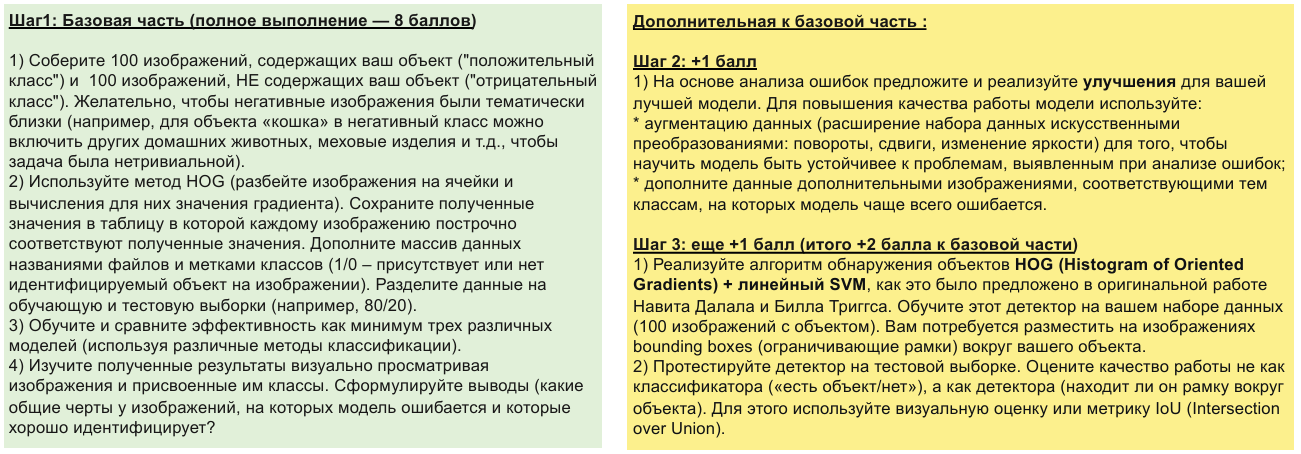

HOG (Histogram of Oriented Gradients) - это метод компьютерного зрения, который используется для извлечения особых признаков из изображений. Он был предложен в 2005 году для задачи обнаружения объектов, особенно для обнаружения людей.

Основная идея метода HOG заключается в том, чтобы описать локальные градиенты яркости или направления краев в изображении. Для этого изображение разделяется на маленькие ячейки, и в каждой ячейке вычисляются градиенты яркости. Затем градиенты объединяются в гистограммы направлений, которые представляют распределение направлений градиентов в ячейке. Наконец, гистограммы объединяются в блоки, чтобы получить окончательное представление признаков.

Алгоритм HOG:

1. (необязательно) Глобальная нормализация изображения

2. Вычисление градиентного изображения по x и y

3. Вычисление градиентных гистограмм

4. Нормализация по блокам

5. Сведение в вектор признаков

На первом этапе применяется дополнительная глобальная корректировка нормализации изображения, предназначенная для уменьшения влияния эффектов освещения.

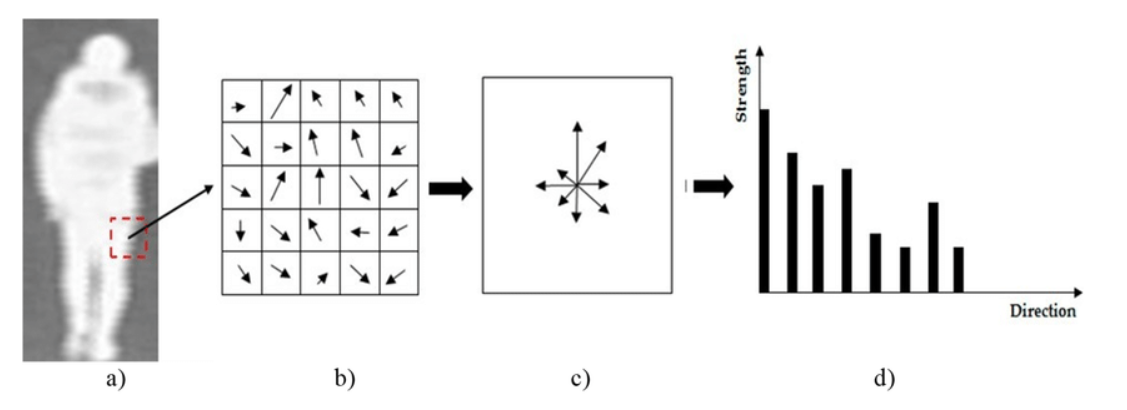!



Демонстрация метода извлечения признаков HOG:

а) входное изображение;

б) карта градиента с силой градиента и направлением субблока входного изображения;

в) ориентация накопленного градиента;

г) гистограмма ориентированных градиентов

[Источник](https://www.researchgate.net/figure/A-demonstration-of-the-HOG-feature-extraction-method-a-the-input-image-b-gradient-map_fig2_352419028)



[Оригинальная статья, с описанием метода](https://ieeexplore.ieee.org/document/1467360)

Что такое "градиент изображения"?

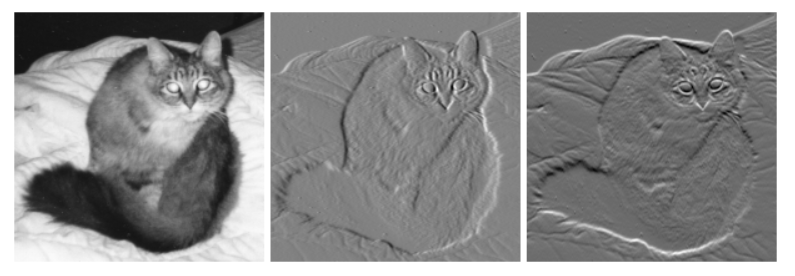

Подробнее читайте тут: [Википедия](https://en.wikipedia.org/wiki/Image_gradient)

In [ ]:
# установим необходимую библиотеку
%pip install scikit-image

In [ ]:
import os
import numpy as np
import pandas as pd

from skimage.feature import hog
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_curve, roc_auc_score, confusion_matrix

from sklearn.neighbors import KNeighborsClassifier

In [ ]:
from google.colab import drive
drive.mount('/content/drive') # вы можете подключить свой аккаунт гугл

Mounted at /content/drive


In [ ]:
import os

data_dir = '/content/drive/MyDrive/IDlab/машинное_обучение/data_sem_8' # для запуска кода у себя загрузите данные себе на диск и измените путь
# данные: https://drive.google.com/drive/folders/1c9exakNZZHkhhghVlJ-bmYn0fOc7Asgc?usp=sharing

cows_dir = os.path.join(data_dir, 'cows')
landscapes_dir = os.path.join(data_dir, 'landscapes')

In [ ]:
for folder in [cows_dir, landscapes_dir]:
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    print(f'{os.path.basename(folder)}: {len(images)} изображений')

cows: 50 изображений
landscapes: 50 изображений


In [ ]:
X = []
y = []

# Коровы — положительный класс (1)
for filename in os.listdir(cows_dir):
    path = os.path.join(cows_dir, filename)
    image = imread(path)

    X.append(image)
    y.append(1)

# Пейзажи — отрицательный класс (0)
for filename in os.listdir(landscapes_dir):
    path = os.path.join(landscapes_dir, filename)
    image = imread(path)

    X.append(image)
    y.append(0)

y = np.array(y)

print('Всего изображений:', len(X))
print('Коров:', sum(y == 1))
print('Пейзажей:', sum(y == 0))

Всего изображений: 100
Коров: 50
Пейзажей: 50


In [ ]:
X_resized = []

for image in X:
    resized = resize(image, (100, 100), anti_aliasing=True)
    X_resized.append(resized)

X_resized = np.array(X_resized)

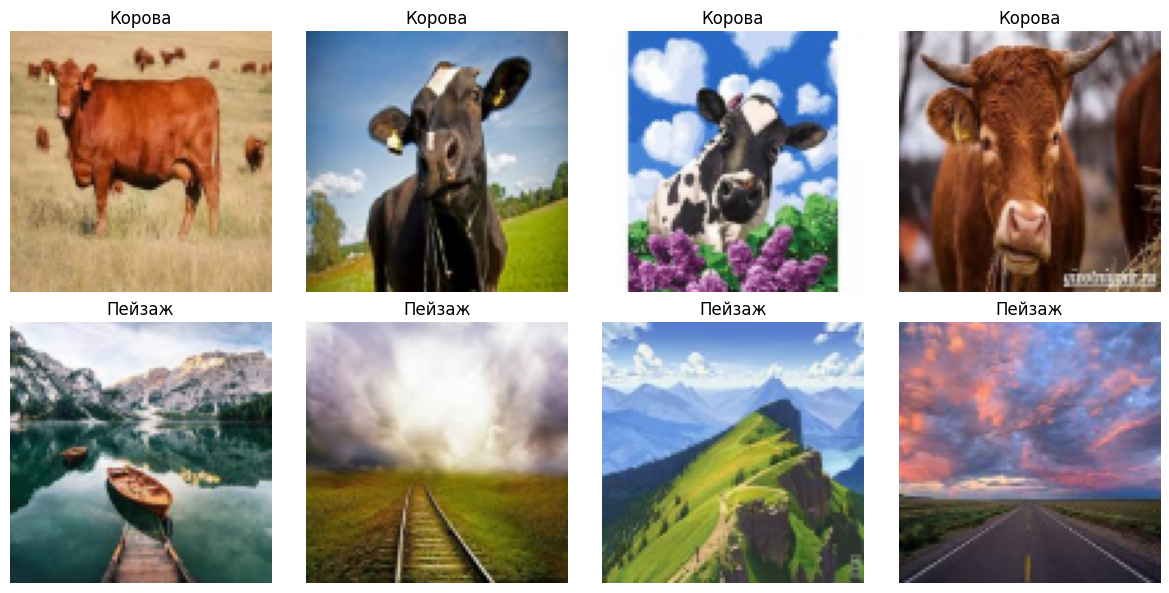

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# Индексы: первые 4 коровы и первые 4 пейзажа
indices = [0, 1, 2, 3, 50, 51, 52, 53]

for i, ax in zip(indices, axes.flat):
    ax.imshow(X_resized[i])
    ax.axis('off')
    ax.set_title('Корова' if y[i] == 1 else 'Пейзаж')

plt.tight_layout()
plt.show()

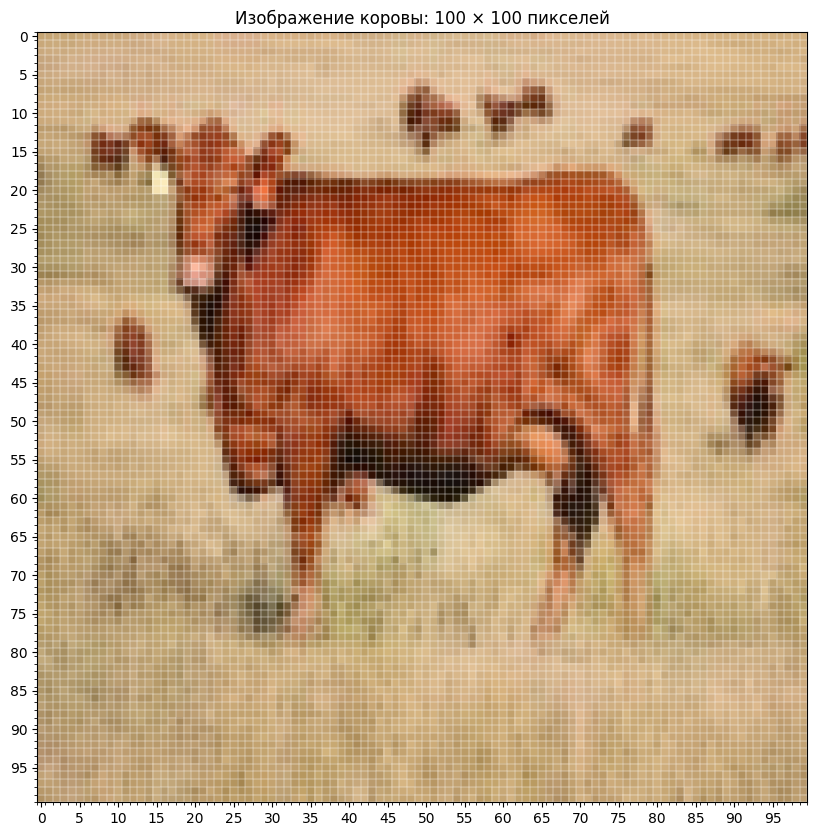

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(X_resized[0])

ax.set_xticks(np.arange(0, 100, 5))
ax.set_yticks(np.arange(0, 100, 5))

ax.set_xticks(np.arange(-0.5, 100, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 100, 1), minor=True)

ax.grid(which='minor', color='white', linestyle='-', linewidth=0.3)

ax.set_title('Изображение коровы: 100 × 100 пикселей')

plt.show()

In [ ]:
print('Размер изображения:', X_resized[0].shape)

print('\nЗначение пикселя (10, 20):')
print(X_resized[0][10, 20])

Размер изображения: (100, 100, 3)

Значение пикселя (10, 20):
[0.82438086 0.69158557 0.51938907]


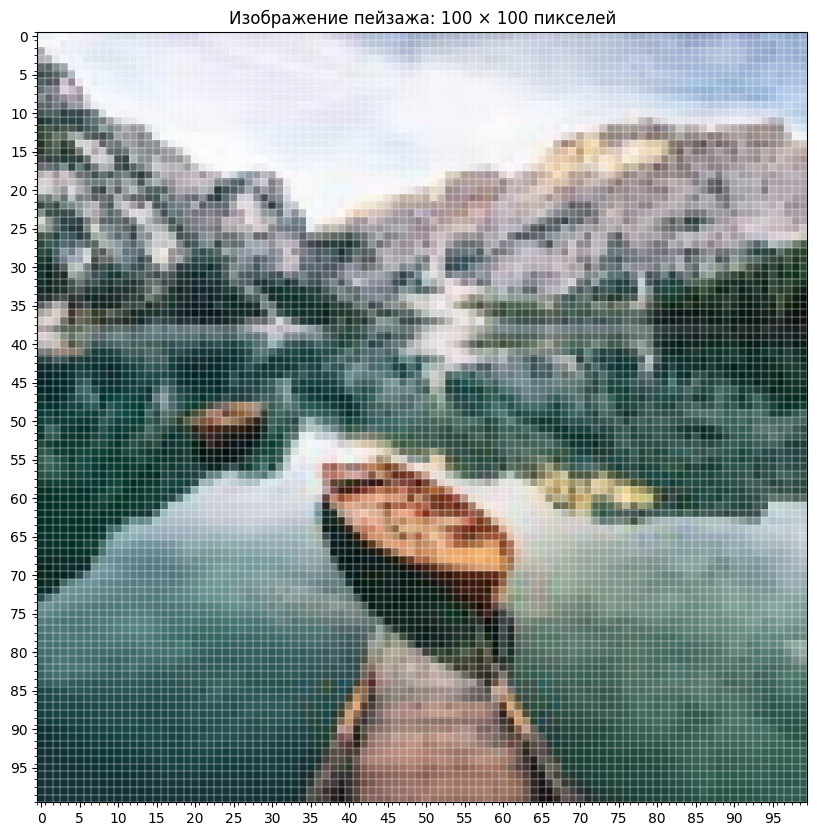

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(X_resized[50])

ax.set_xticks(np.arange(0, 100, 5))
ax.set_yticks(np.arange(0, 100, 5))

ax.set_xticks(np.arange(-0.5, 100, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 100, 1), minor=True)

ax.grid(which='minor', color='white', linestyle='-', linewidth=0.3)

ax.set_title('Изображение пейзажа: 100 × 100 пикселей')

plt.show()

In [ ]:
print('Размер изображения:', X_resized[50].shape)

print('\nЗначение пикселя (10, 20):')
print(X_resized[50][10, 20])

Размер изображения: (100, 100, 3)

Значение пикселя (10, 20):
[0.95906713 0.96292702 0.98267269]


Мы используем HOG, потому что хотим описывать не цвет каждого пикселя, а локальные границы и форму объектов. Это позволяет получить компактное признаковое представление изображения, которое можно использовать для классического машинного обучения.

## Рассмотрим суть метода на одном примере

### Переводим изображение в черно-белое

Возьмём первую корову из нашего набора. Для HOG будем использовать изображение в оттенках серого.

HOG не использует цвет как основной признак. Нам важно понять, где происходят изменения яркости, поскольку именно они позволяют выделять контуры и форму объекта.

In [ ]:
# Берём первую корову
image = X_resized[0]

# Переводим в оттенки серого
gray = np.dot(image[..., :3], [0.2125, 0.7154, 0.0721])

print('Размер изображения:', gray.shape)

Размер изображения: (100, 100)


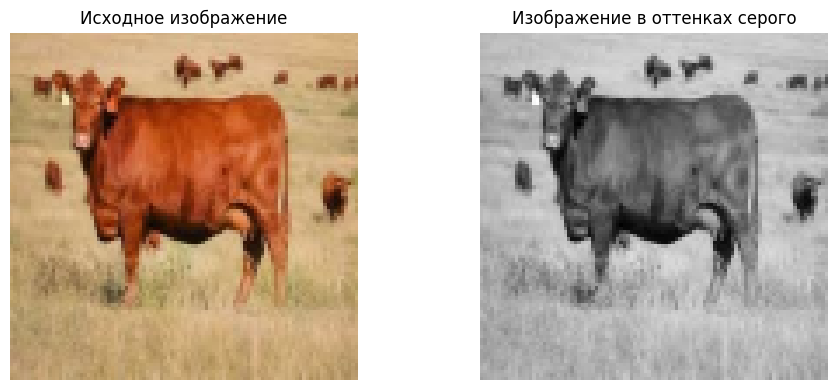

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title('Исходное изображение')
axes[0].axis('off')

axes[1].imshow(gray, cmap='gray')
axes[1].set_title('Изображение в оттенках серого')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Как изображение превращается в числа

После перевода в оттенки серого у нас есть матрица 100 × 100. Каждая ячейка содержит интенсивность пикселя (яркость) от 0 до 1.

**Что такое яркость изображения?**

Яркость (интенсивность пикселя) — это числовая характеристика, которая показывает, насколько светлым или темным является конкретный пиксель изображения.

В нашем случае мы перевели цветное изображение в оттенки серого. Поэтому вместо трех значений цветовых каналов (R, G, B) у каждого пикселя осталось одно значение — интенсивность.

Она находится в диапазоне от 0 до 1:

| Значение |	Цвет |	Интерпретация |
| -------- | ----------------- | ------------------------------------- |
| 0.00 |	Чёрный |	Минимальная интенсивность |
| 0.25 |	Тёмно-серый |	Низкая интенсивность |
| 0.50 |	Серый |	Средняя интенсивность |
| 0.75 |	Светло-серый |	Высокая интенсивность |
| 1.00 |	Белый |	Максимальная интенсивность |

**Как рассчитывается яркость?**

Когда мы переводим цветное изображение в оттенки серого, используем формулу:

$$
I = 0.2125R + 0.7154G + 0.0721B
$$

Где:
- $R$ — интенсивность красного канала;
- $G$ — интенсивность зелёного канала;
- $B$ — интенсивность синего канала.

**Почему коэффициенты разные?** Потому что человеческий глаз неодинаково воспринимает разные цвета: зеленый вносит больший вклад в воспринимаемую яркость, чем красный и синий.

Связь с HOG: алгоритму важно не столько то, насколько ярким является отдельный пиксель, сколько то, насколько сильно яркость меняется между соседними пикселями. Именно на этих изменениях основано вычисление градиентов и выделение контуров объектов.

### Посмотрим на небольшой фрагмент 10 × 10:

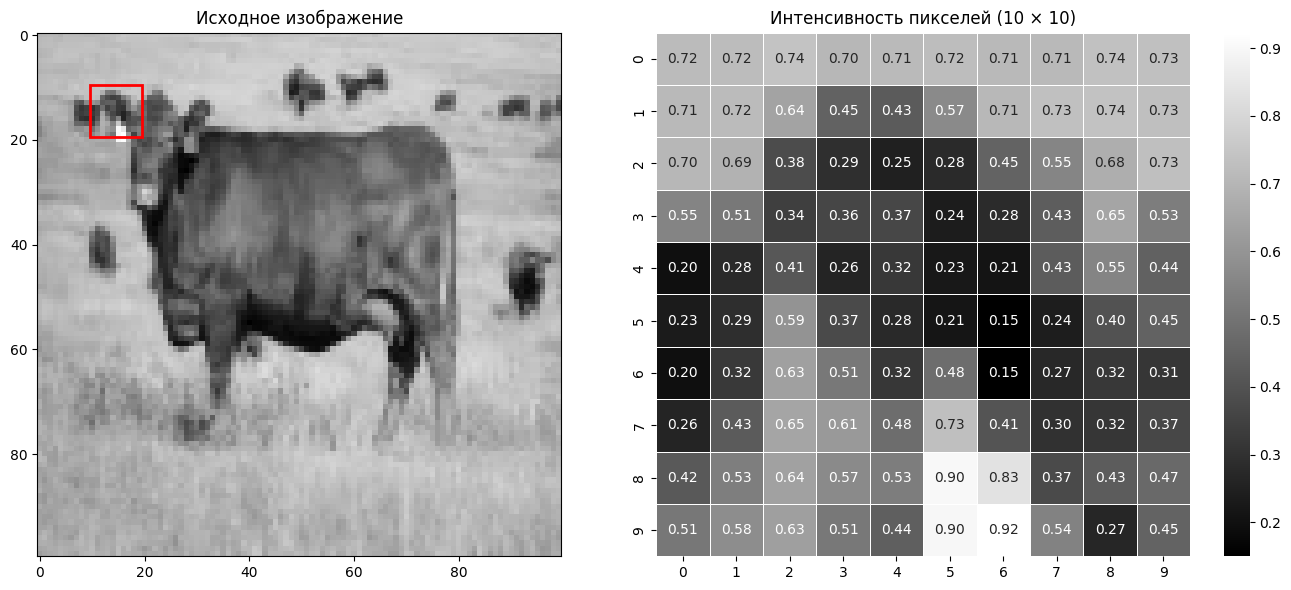

In [ ]:
# Координаты рассматриваемого фрагмента
y_start, y_end = 10, 20
x_start, x_end = 10, 20

# Выбираем фрагмент
fragment = gray[y_start:y_end, x_start:x_end]

# Создаём два графика
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Исходное изображение с выделенным фрагментом
axes[0].imshow(gray, cmap='gray')
rect = plt.Rectangle(
    (x_start - 0.5, y_start - 0.5),
    x_end - x_start,
    y_end - y_start,
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)
axes[0].add_patch(rect)
axes[0].set_title('Исходное изображение')

# Матрица интенсивностей выбранного фрагмента
sns.heatmap(
    fragment,
    annot=True,
    fmt='.2f',
    cmap='gray',
    cbar=True,
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title('Интенсивность пикселей (10 × 10)')

plt.tight_layout()
plt.show()

### Вычисление градиентов с помощью фильтров Собеля

Градиент изображения показывает, насколько сильно и в каком направлении меняется яркость между соседними пикселями.

Для вычисления градиентов используем **фильтры Собеля** (Sobel filters) из библиотеки `scikit-image`.

Они позволяют определить две составляющие градиента:

- $G_x$ — изменение яркости по горизонтали;
- $G_y$ — изменение яркости по вертикали.

На основе этих составляющих рассчитываются две характеристики:

**1. Величина градиента (magnitude)** — показывает, насколько сильно меняется яркость. Чем больше значение, тем более выражено изменение яркости.

**2. Направление градиента (orientation)** — показывает, в каком направлении происходит изменение яркости.

Почему это важно для HOG?

На границах объектов яркость обычно меняется достаточно резко, поэтому величина градиента там выше. Направления градиентов помогают описать ориентацию локальных границ и особенности формы объектов.

Таким образом, вместо анализа самих значений яркости мы переходим к анализу их изменений.

In [ ]:
from skimage.filters import sobel_h, sobel_v

- sobel_v вычисляет изменение по горизонтали (градиент $G_x$);
- sobel_h вычисляет изменение по вертикали (градиент $G_y$).

In [ ]:
# Вычисляем компоненты градиента
Gx = sobel_v(fragment)
Gy = sobel_h(fragment)

# Вычисляем величину градиента
magnitude = np.sqrt(Gx**2 + Gy**2)

# Вычисляем направление градиента
orientation = np.degrees(np.arctan2(Gy, Gx)) % 180

print('Размер матрицы градиентов:', magnitude.shape)

Размер матрицы градиентов: (10, 10)


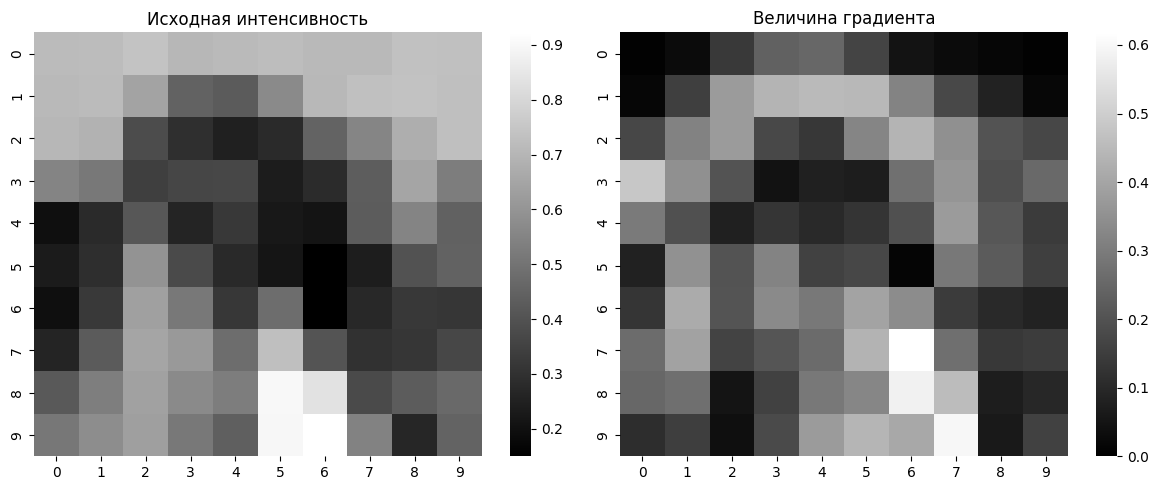

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Исходный фрагмент
sns.heatmap(
    fragment,
    cmap='gray',
    cbar=True,
    ax=axes[0]
)
axes[0].set_title('Исходная интенсивность')

# Величина градиента
sns.heatmap(
    magnitude,
    cmap='gray',
    vmin=0,
    vmax=magnitude.max(),
    cbar=True,
    ax=axes[1]
)
axes[1].set_title('Величина градиента')

plt.tight_layout()
plt.show()

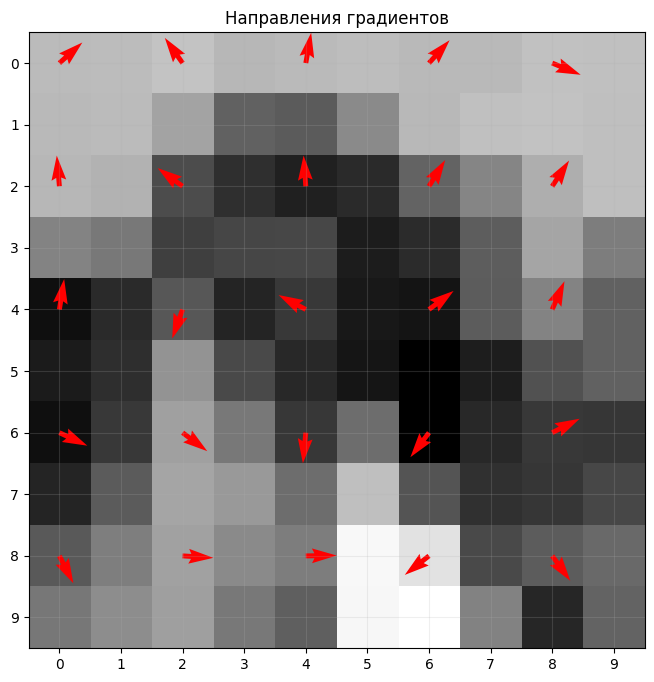

In [ ]:
# Создаём координатную сетку
Y, X = np.mgrid[0:10, 0:10]

# Нормализуем градиенты: оставляем направление, убираем различия в длине
eps = 1e-8
U = Gx / (magnitude + eps)
V = Gy / (magnitude + eps)

fig, ax = plt.subplots(figsize=(8, 8))

# Исходный фрагмент
ax.imshow(fragment, cmap='gray')

# Стрелки градиентов
ax.quiver(
    X[::2, ::2],
    Y[::2, ::2],
    U[::2, ::2],
    V[::2, ::2],
    color='red',
    angles='xy',
    scale_units='xy',
    scale=2,
    width=0.008
)

ax.set_title('Направления градиентов')
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.grid(alpha=0.2)

plt.show()

- На карте величины градиента светлые области соответствуют более сильным изменениям яркости, тёмные — более слабым.
- Стрелки показывают направления градиентов в отдельных пикселях.
- На однородных участках изображения градиенты обычно слабее, а вблизи границ объектов — сильнее.

### Как отдельные градиенты превращаются в описание контуров

1. Градиенты отдельных пикселей (это мы сделали выше)

Для каждого пикселя определяем, насколько сильно и в каком направлении меняется яркость относительно соседних пикселей. На границах объектов изменения яркости обычно выражены сильнее.

2. Группировка градиентов в ячейках

Вместо анализа каждого пикселя отдельно объединяем градиенты внутри небольших областей (например, 8 × 8 пикселей). Для каждой области строим гистограмму направлений. Она показывает, какие направления градиентов преобладают.

3. Объединение соседних ячеек в блоки

Гистограммы соседних ячеек нормализуются совместно. Это позволяет учитывать локальную структуру изображения и уменьшать влияние изменений освещения и контраста.

4. Формирование описания объекта

В соседних ячейках могут наблюдаться согласованные направления градиентов. Например, последовательно меняющиеся направления вдоль границы туловища коровы формируют характерный пространственный рисунок. Совокупность таких рисунков позволяет описывать форму объекта.

- Ячейка (cell) — небольшая область изображения, в которой строится гистограмма направлений градиентов.
- Блок (block) — группа соседних ячеек, внутри которой выполняется нормализация гистограмм.

Соседние блоки перекрываются, поэтому одна ячейка может участвовать в нескольких блоках. Это помогает сделать описание изображения более устойчивым к небольшим изменениям положения границ.

In [ ]:
features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm='L2',
    visualize=True
)

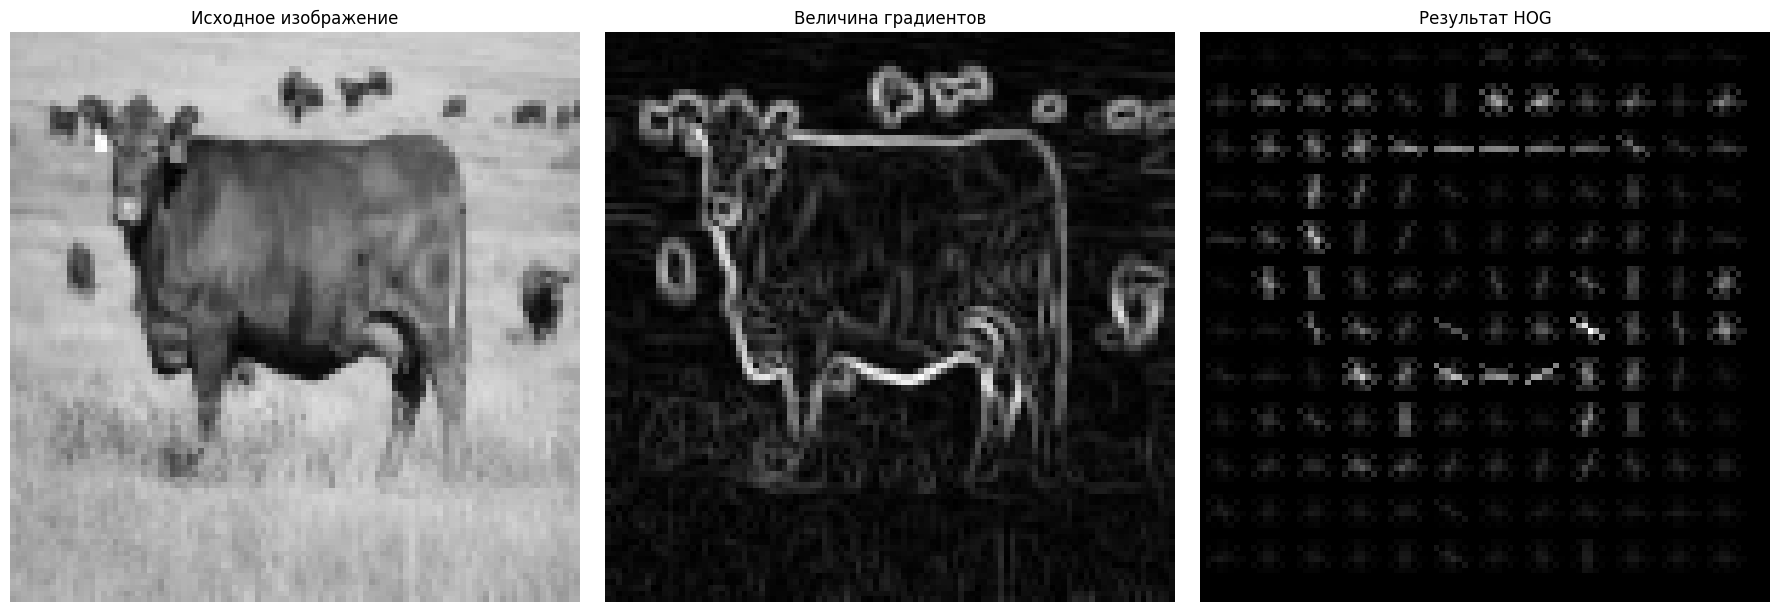

In [ ]:
from skimage.filters import sobel_h, sobel_v

# Вычисляем градиенты
Gx = sobel_v(gray)
Gy = sobel_h(gray)

# Вычисляем величину градиента
magnitude = np.sqrt(Gx**2 + Gy**2)

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Исходное изображение')
axes[0].axis('off')

axes[1].imshow(magnitude, cmap='gray')
axes[1].set_title('Величина градиентов')
axes[1].axis('off')

axes[2].imshow(hog_image, cmap='gray')
axes[2].set_title('Результат HOG')
axes[2].axis('off')

plt.tight_layout()
plt.show()

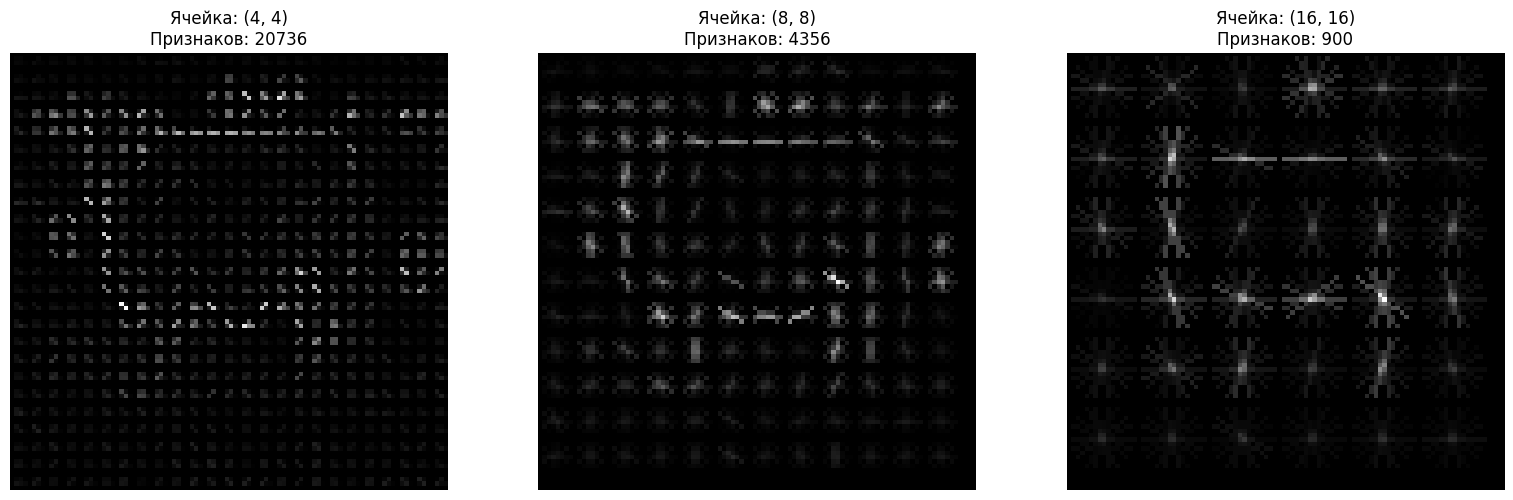

In [ ]:
params = [
    {'pixels_per_cell': (4, 4), 'cells_per_block': (2, 2)},
    {'pixels_per_cell': (8, 8), 'cells_per_block': (2, 2)},
    {'pixels_per_cell': (16, 16), 'cells_per_block': (2, 2)}
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, param in zip(axes, params):
    f, h = hog(
        gray,
        orientations=9,
        pixels_per_cell=param['pixels_per_cell'],
        cells_per_block=param['cells_per_block'],
        block_norm='L2',
        visualize=True
    )

    ax.imshow(h, cmap='gray')
    ax.set_title(
        f"Ячейка: {param['pixels_per_cell']}\n"
        f"Признаков: {len(f)}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

**Важное уточнение:** HOG сам по себе не определяет, где начинается и заканчивается корова, и не соединяет линии в единый контур. Он формирует числовой вектор, сохраняющий информацию о локальных направлениях градиентов и их пространственном расположении. Уже классификатор учится находить в этом описании закономерности, характерные для коров или пейзажей.

In [ ]:
# Выводим вектор признаков для одной коровы
print('Вектор признаков HOG:')
print(features)

print('\nРазмер вектора:', features.shape)
print('Количество признаков:', len(features))

Вектор признаков HOG:
[0.02369623 0.04276967 0.01077665 ... 0.10885473 0.12296053 0.19812615]

Размер вектора: (4356,)
Количество признаков: 4356


## Перейдем к обработке всего массива изображений

In [ ]:
X_hog = []
y_hog = []

for image, label in zip(X_resized, y):

    # Переводим изображение в оттенки серого
    gray = np.dot(image[..., :3], [0.2125, 0.7154, 0.0721])

    # Извлекаем HOG-признаки
    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2',
        feature_vector=True
    )

    X_hog.append(features)
    y_hog.append(label)

X_hog = np.array(X_hog)
y_hog = np.array(y_hog)

print('Размер матрицы признаков:', X_hog.shape)
print('Размер вектора классов:', y_hog.shape)

Размер матрицы признаков: (100, 4356)
Размер вектора классов: (100,)


In [ ]:
print('Количество изображений с коровами:', np.sum(y_hog == 1))
print('Количество изображений с пейзажами:', np.sum(y_hog == 0))

Количество изображений с коровами: 50
Количество изображений с пейзажами: 50


## Классифицируем изображения на основе полученных признаков

### Делим выборку на обучающую и тестовую

In [ ]:
indices = np.arange(len(y_hog))

train_idx, test_idx, y_train, y_test = train_test_split(
    indices,
    y_hog,
    test_size=0.2,
    random_state=42,
    stratify=y_hog
)

X_train = X_hog[train_idx]
X_test = X_hog[test_idx]

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Обучающая выборка: (80, 4356)
Тестовая выборка: (20, 4356)


### Обучим модель

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Создаём модель
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1, gamma='scale'))
])

# Обучаем модель
svm_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC(C=1))])

### Получим предсказания

In [ ]:
y_pred = svm_model.predict(X_test)

### Качество модели

Полученное качество характеризует результат на конкретном разбиении небольшой выборки. Для более надёжной оценки обобщающей способности модели можно использовать кросс-валидацию и дополнительные изображения.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print('Accuracy:', accuracy_score(y_test, y_pred))

print('\nClassification report:')
print(classification_report(
    y_test,
    y_pred,
    target_names=['Пейзаж', 'Корова']
))

Accuracy: 0.8

Classification report:
              precision    recall  f1-score   support

      Пейзаж       0.88      0.70      0.78        10
      Корова       0.75      0.90      0.82        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



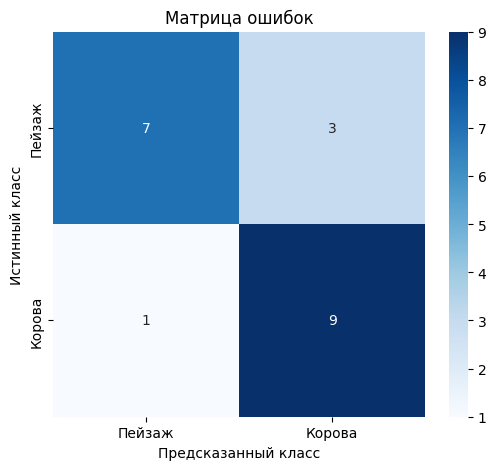

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Пейзаж', 'Корова'],
    yticklabels=['Пейзаж', 'Корова']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок')
plt.show()

In [ ]:
# Находим позиции, где предсказанный класс не совпадает с истинным
errors = np.where(y_test != y_pred)[0]

print('Количество ошибок:', len(errors))
print('Индексы ошибочных изображений в тестовой выборке:', errors)

Количество ошибок: 4
Индексы ошибочных изображений в тестовой выборке: [ 1 10 12 13]


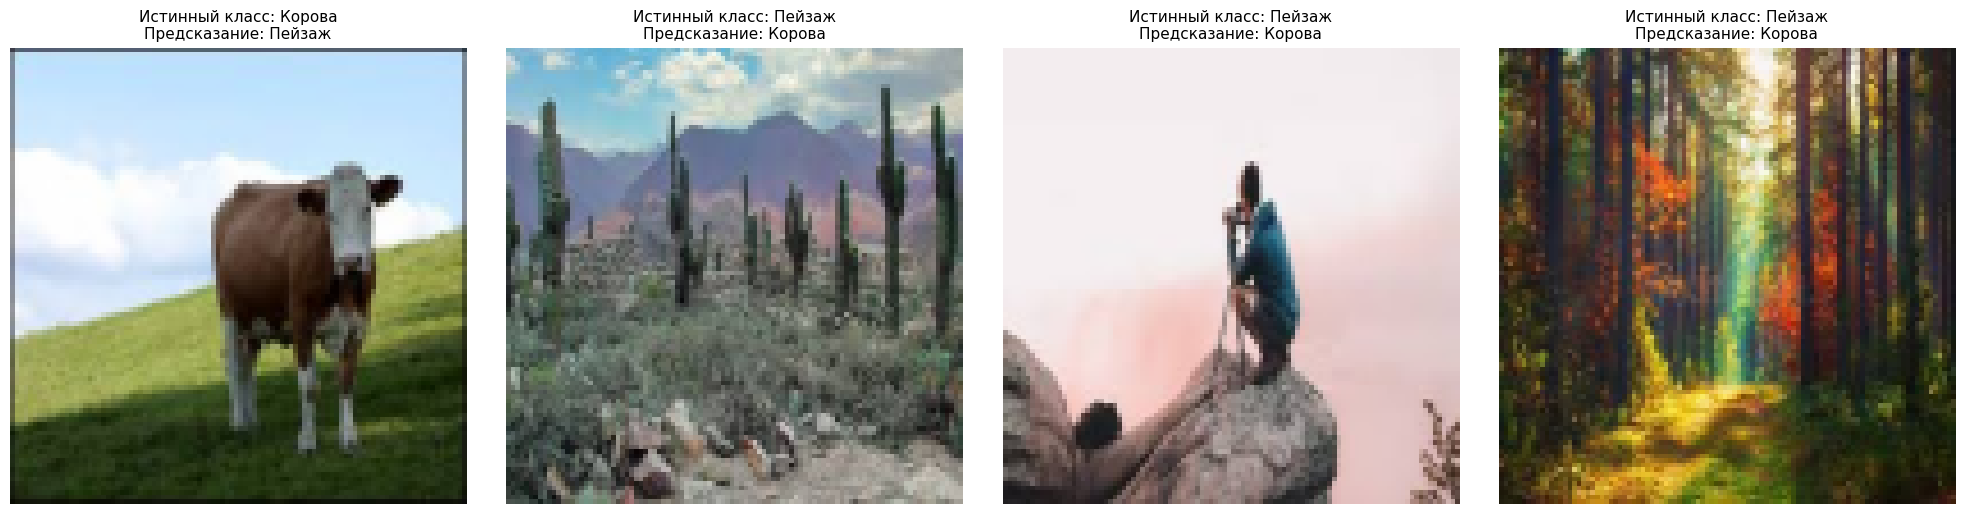

In [ ]:
fig, axes = plt.subplots(
    1, len(errors),
    figsize=(5 * len(errors), 5)
)

if len(errors) == 1:
    axes = [axes]

for ax, error_idx in zip(axes, errors):

    # Получаем индекс изображения в исходном датасете
    original_idx = test_idx[error_idx]

    # Истинный и предсказанный классы
    true_label = 'Корова' if y_test[error_idx] == 1 else 'Пейзаж'
    pred_label = 'Корова' if y_pred[error_idx] == 1 else 'Пейзаж'

    ax.imshow(X_resized[original_idx])
    ax.set_title(
        f'Истинный класс: {true_label}\n'
        f'Предсказание: {pred_label}',
        fontsize=11
    )
    ax.axis('off')

plt.tight_layout()
plt.show()